# Supplementary Fig. 1: Xenium multimodal cell segmentation

Xenium multimodal cell segmentation is far less reproducible than its nuclear segmentation.
The Xenium onboard nuclear and multimodal cell masks of three sections are compared with Cellpose-SAM run on the same stains.

| | |
|---|---|
| Data | Morphology images and onboard label images (`cells.zarr.zip`) of three Xenium sections with the multimodal cell segmentation stains: colorectal cancer (`xenium_crc`), lung cancer and Xenium Prime breast cancer (`xenium_breast`) |
| Compute | CUDA GPU for Cellpose-SAM. Whole-section masks and per-tile scores are cached in `results/supp_figure_1`. |
| Output | `results/supp_figure_1/panel_{a,b,c}.{pdf,png}` |

The lung cancer section ([10x Genomics, FFPE Human Lung Cancer with Xenium Multimodal Cell Segmentation](https://www.10xgenomics.com/datasets/preview-data-ffpe-human-lung-cancer-with-xenium-multimodal-cell-segmentation-1-standard)) is not in `sg_utils.datasets`; its output bundle is expected in `DATA_DIR/xenium_lung_multimodal/xenium`.

In [1]:
import json
import logging
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", category=FutureWarning)  # deprecation notices raised on import

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import scanpy as sc
import seaborn as sns
from cellpose.models import CellposeModel
from matplotlib.collections import PolyCollection
from segger.io.utils import contours_to_polygons, fix_invalid_geometry, masks_to_contours
from shapely.plotting import patch_from_polygon

import sg_utils as sg
from sg_utils.tl.masks import mask_agreement, read_morphology_image, read_xenium_masks, segment_tiled, tiled_rand_index

logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
logging.getLogger("cellpose").setLevel(logging.ERROR)
ASSETS = Path(sg.pl.__file__).parent / "assets"
plt.style.use(ASSETS / "default.mplstyle")
plt.rcParams["savefig.bbox"] = "tight"
palettes = json.loads((ASSETS / "palettes.json").read_text())
boundary_palette = {"nucleus": palettes["Method"]["10x Nucleus"], "cell": palettes["Method"]["10x Cell"]}

In [2]:
DATA_DIR = Path("../data")
OUT_DIR = Path("../results/supp_figure_1")

## Download the data

In [3]:
xenium_dirs = {
    "xenium_crc": sg.datasets.fetch("xenium_crc", DATA_DIR, files=["xenium", "masks"])["xenium"],
    "xenium_lung_multimodal": DATA_DIR / "xenium_lung_multimodal" / "xenium",
    "xenium_breast": sg.datasets.fetch("xenium_breast", DATA_DIR, files=["xenium", "masks"])["xenium"],
}
SAMPLES = {
    "xenium_crc": "Xenium v1.0\nColorectal Cancer",
    "xenium_lung_multimodal": "Xenium v1.0\nLung",
    "xenium_breast": "Xenium Prime\nBreast Cancer",
}
BOUNDARIES = ["nucleus", "cell"]
MPP = 0.2125  # µm per pixel of the morphology images
OUT_DIR.mkdir(parents=True, exist_ok=True)

## Cellpose-SAM masks

Nuclei from DAPI, cells from DAPI with the boundary and interior stains, segmented tile by tile with the default Cellpose-SAM model.
Masks are cached in `OUT_DIR`.

In [4]:
for sample, xenium_dir in xenium_dirs.items():
    paths = {b: OUT_DIR / f"{sample}_{b}_cellpose_masks.npy" for b in BOUNDARIES}
    if all(path.exists() for path in paths.values()):
        continue
    image = read_morphology_image(xenium_dir / "morphology_focus")
    for boundary, path in paths.items():
        if path.exists():
            continue
        channels = image[:, :, 0] if boundary == "nucleus" else image
        np.save(path, segment_tiled(channels, model=CellposeModel(gpu=True), tile_size=20_000, batch_size=300))
    del image

## Agreement per tile

Adapted Rand index between the onboard and Cellpose-SAM masks in each 250 × 250 pixel (53 µm) tile, keeping tiles with more than five labels in both.

In [5]:
path_scores = OUT_DIR / "segmentation_agreement.parquet"
if path_scores.exists():
    scores = pl.read_parquet(path_scores)
else:
    frames = []
    for sample, xenium_dir in xenium_dirs.items():
        for boundary in BOUNDARIES:
            masks_10x = read_xenium_masks(xenium_dir / "cells.zarr.zip", boundary)
            masks_cellpose = np.load(OUT_DIR / f"{sample}_{boundary}_cellpose_masks.npy")
            frames.append(
                tiled_rand_index(masks_10x, masks_cellpose, tile_size=250)
                .with_columns(pl.lit(sample).alias("sample"), pl.lit(boundary).alias("boundary"))
            )
    scores = pl.concat(frames)
    scores.write_parquet(path_scores)
scores = scores.filter(pl.col("n_labels_left").gt(5) & pl.col("n_labels_right").gt(5))

## Panels a and b: one field of view

A 250 µm field of the colorectal cancer section, re-segmented with Cellpose-SAM; left, the stains; right, area assigned by both segmentations (green) or only one (red), with both sets of outlines.

In [6]:
TILE_SIZE = 250
EPS = 10
X0, Y0 = 3900, 2620
fov_dir = xenium_dirs["xenium_crc"]
bounds = (X0 - EPS, X0 + TILE_SIZE + EPS, Y0 - EPS, Y0 + TILE_SIZE + EPS)
xmin, xmax, ymin, ymax = bounds
selection = (slice(int(ymin / MPP), int(ymax / MPP)), slice(int(xmin / MPP), int(xmax / MPP)))


def smooth(polygons):
    polygons = fix_invalid_geometry(polygons)
    polygons["geometry"] = polygons.geometry.buffer(1).buffer(-2).buffer(1)
    return polygons


def load_boundary_polygons(path, bounds):
    """Xenium boundary polygons intersecting ``(xmin, xmax, ymin, ymax)``, in µm."""
    xmin, xmax, ymin, ymax = bounds
    vertices = (
        pl.read_parquet(path)
        .filter(pl.col("vertex_x").is_between(xmin, xmax) & pl.col("vertex_y").is_between(ymin, ymax))
        .filter(pl.col("cell_id").count().over("cell_id").ge(4))
    )
    return smooth(contours_to_polygons(
        vertices["vertex_x"].to_numpy(), vertices["vertex_y"].to_numpy(), vertices["cell_id"].to_numpy(),
    ))


def segment_field(image, bounds):
    """Cellpose-SAM polygons of an image crop, in µm."""
    xmin, _, ymin, _ = bounds
    masks, _, _ = CellposeModel(gpu=True).eval(image)
    return smooth(gpd.GeoDataFrame(
        geometry=contours_to_polygons(*masks_to_contours(masks).T).scale(MPP, MPP, origin=(0, 0)).translate(xmin, ymin)
    ))


field = dict()
for boundary in BOUNDARIES:
    channels = (0,) if boundary == "nucleus" else (0, 1, 2)
    image = read_morphology_image(fov_dir / "morphology_focus", channels=channels, selection=selection)
    polygons_10x = load_boundary_polygons(fov_dir / f"{boundary}_boundaries.parquet", bounds)
    polygons_cellpose = segment_field(image, bounds)
    shared, exclusive = mask_agreement(polygons_10x, polygons_cellpose)
    field[boundary] = dict(
        image=image, polygons_10x=polygons_10x, polygons_cellpose=polygons_cellpose, shared=shared, exclusive=exclusive,
    )

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.0033222593..1.3828903].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.009607523..1.4839214].


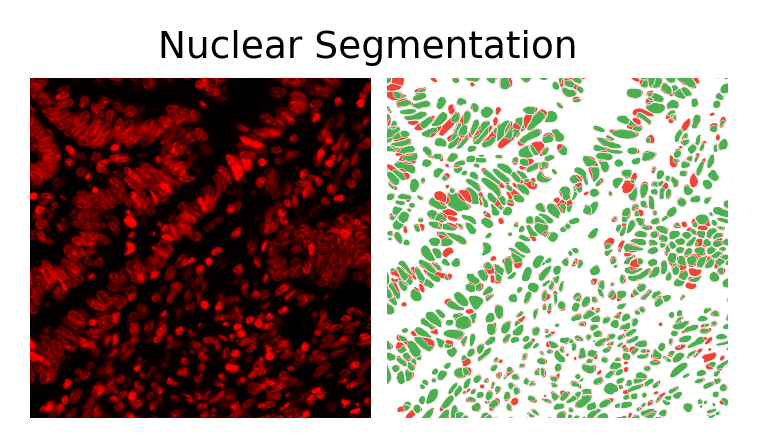

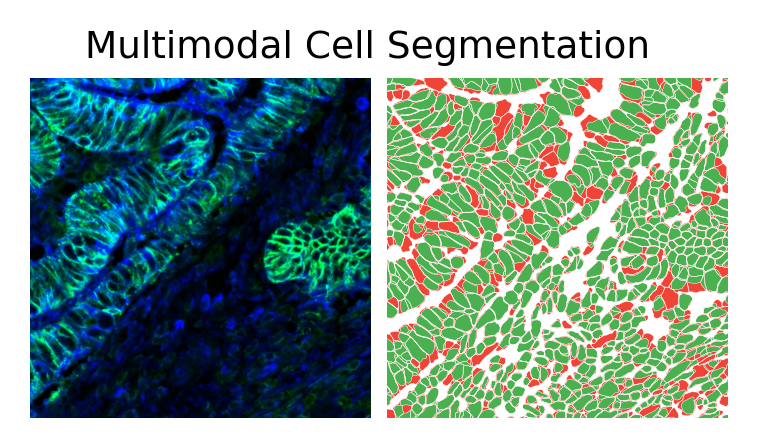

In [7]:
titles = {"nucleus": "Nuclear Segmentation", "cell": "Multimodal Cell Segmentation"}
for panel, boundary in zip("ab", BOUNDARIES):
    entry = field[boundary]
    fig, (ax_stain, ax_masks) = plt.subplots(1, 2, figsize=(3, 1.5), gridspec_kw=dict(wspace=0.05))
    if boundary == "nucleus":
        rgb = np.pad(entry["image"], ((0, 0), (0, 0), (0, 2)))
    else:
        rgb = entry["image"].copy()
        rgb[:, :, 0] = 0
    ax_stain.imshow(rgb, extent=(xmin, xmax, ymin, ymax), origin="lower", zorder=-1)
    ax_masks.set_facecolor("black")
    for geometry, color in [(entry["shared"], "#4BB04F"), (entry["exclusive"], "#F04437")]:
        ax_masks.add_patch(patch_from_polygon(geometry, lw=0, facecolor=color, zorder=0))
    for key in ["polygons_10x", "polygons_cellpose"]:
        coords = entry[key].geometry.get_coordinates()
        splits = np.unique(coords.index, return_index=True)[1][1:]
        ax_masks.add_collection(PolyCollection(
            np.split(coords.to_numpy(), splits), facecolor="none", edgecolor="w", lw=0.1, zorder=1,
        ))
    for ax in (ax_stain, ax_masks):
        ax.set_xlim(X0, X0 + TILE_SIZE)
        ax.set_ylim(Y0, Y0 + TILE_SIZE)
        ax.set_aspect("equal")
        ax.axis("off")
    fig.suptitle(titles[boundary], fontsize=9)
    sg.pl.save_panel(fig, OUT_DIR / f"panel_{panel}")

## Panel c: agreement with Cellpose-SAM

Adapted Rand index of the nuclear (red) and multimodal cell (blue) segmentations; bars, median over tiles; whiskers, interquartile range.

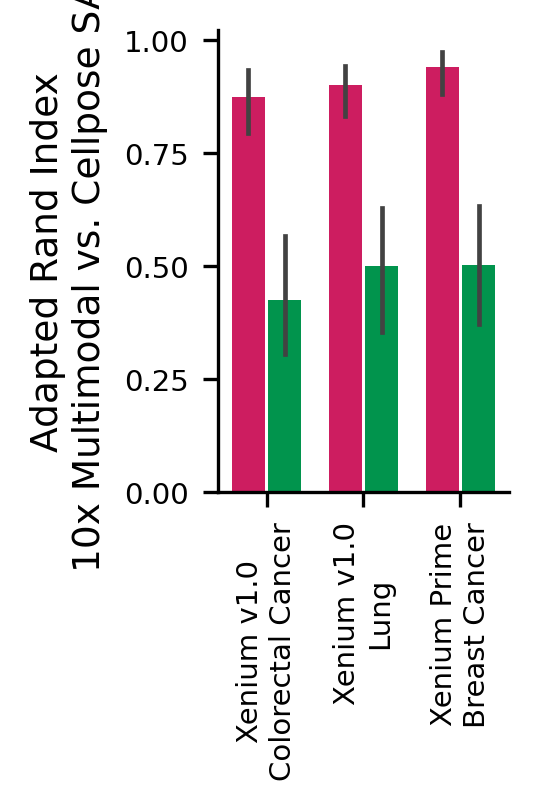

In [8]:
fig, ax = plt.subplots(1, 1, figsize=(1.25, 2))
sns.barplot(
    scores, x="sample", y="rand_index", hue="boundary", order=list(SAMPLES), hue_order=BOUNDARIES,
    palette=boundary_palette, estimator="median", errorbar=("pi", 50), width=0.75, gap=0.1, saturation=1,
    legend=False, ax=ax,
)
ax.set_xticks(range(len(SAMPLES)), list(SAMPLES.values()), rotation=90)
ax.set_yticks(np.arange(0, 1.1, 0.25))
ax.set_xlabel("")
ax.set_ylabel("Adapted Rand Index\n10x Multimodal vs. Cellpose SAM")
sg.pl.save_panel(fig, OUT_DIR / "panel_c")

## Software versions

In [9]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    display(sc.logging.print_header())

Package,Version
geopandas,1.1.3
matplotlib,3.10.8
numpy,1.26.4
polars,1.40.0
scanpy,1.11.5
seaborn,0.13.2
cellpose,4.2.1.1
segger,0.1.0
shapely,2.1.2
pandas,2.2.2
